# 01 Confusion views: where do CNN and SNN make *different* mistakes?

Black box. Rows = true class, columns = predicted class, row-normalised. Difference = SNN − CNN on the **same images**: red = the SNN makes this mistake more often. A dot marks cells whose paired 95 % interval excludes 0; unmarked cells are within noise.

Tests H1, H2, H3, H4 from `hypotheses.md`.

In [1]:
%matplotlib inline
import os
import sys
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
sys.path.insert(0, ".")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aiv.load import CLASSES, OUTCOMES, data_source, paired, pick
from aiv.stats import wilson
from lab.config import CORRUPTIONS, SEVERITIES

CNN, SNN = pick()
W = paired(CNN, SNN)
COND = [("clean", 0)] + [(c, s) for c in CORRUPTIONS for s in SEVERITIES]
COL = dict(zip(OUTCOMES, ["#d9d9d9", "#d62728", "#1f77b4", "#7f7f7f", "#ff7f0e"]))
print(f"CNN = {CNN} | SNN = {SNN} | data = {data_source()} | rows = {len(W):,}")

CNN = cnn-float | SNN = snn-sim | data = regenerated CIFAR-10-C (not official) | rows = 160,000


Accuracy per condition, for orientation only (the views below are the analysis).

In [3]:
from aiv.load import accuracy

acc = pd.concat([accuracy(CNN), accuracy(SNN)])
k = (acc.top1 * acc.n_images).round()
acc["ci95"] = [f"[{lo:.3f}, {hi:.3f}]" for lo, hi in zip(*wilson(k, acc.n_images))]
acc.pivot_table(index=["corruption", "severity"], columns="model", values="top1",
                sort=False).round(3)

model                    cnn-float  snn-sim
corruption     severity                    
clean          0             0.762    0.719
fog            1             0.762    0.719
               2             0.732    0.687
               3             0.681    0.640
               4             0.623    0.573
               5             0.477    0.438
gaussian_noise 1             0.690    0.646
               2             0.592    0.568
               3             0.493    0.487
               4             0.452    0.451
               5             0.415    0.415
contrast       1             0.756    0.710
               2             0.636    0.594
               3             0.525    0.474
               4             0.398    0.335
               5             0.259    0.225

## Class order by error similarity
Hierarchical clustering (average linkage) of the symmetrised off-diagonal confusion, both models and all conditions pooled, so classes confused with each other sit together.

In [4]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

def counts(d, m):
    c = np.zeros((10, 10))
    np.add.at(c, (d.label.values, d[f"pred_{m}"].values.astype(int)), 1)
    return c

def rate(d, m):
    c = counts(d, m)
    return c / np.maximum(c.sum(1, keepdims=True), 1)

off = (rate(W, "cnn") + rate(W, "snn")) / 2
np.fill_diagonal(off, 0)
sim = (off + off.T) / 2
dist = 1 - sim / sim.max()
np.fill_diagonal(dist, 0)
ORDER = leaves_list(linkage(squareform(dist, checks=False), "average"))
NAMES = [CLASSES[i] for i in ORDER]
print("order:", NAMES)

order: ['bird', 'deer', 'horse', 'dog', 'cat', 'frog', 'airplane', 'ship', 'automobile', 'truck']


## Paired differences per cell
For true class t and predicted class p: share of t-images the SNN sends to p minus share the CNN sends to p, with a paired (McNemar-style) 95 % interval.

In [5]:
from aiv.stats import paired_diff

rows = []
for (c, s), d in W.groupby(["corruption", "severity"], sort=False):
    for t in range(10):
        dt = d[d.label == t]
        for p in range(10):
            diff, lo, hi, n = paired_diff(dt.pred_cnn.values == p, dt.pred_snn.values == p)
            rows.append((c, s, t, p, diff, lo, hi, n))
DIFF = pd.DataFrame(rows, columns=["corruption", "severity", "t", "p", "diff", "lo", "hi", "n"])
DIFF["sig"] = (DIFF.lo > 0) | (DIFF.hi < 0)
off_sig = DIFF[(DIFF.t != DIFF.p) & DIFF.sig]
print(f"{DIFF.sig[(DIFF.t != DIFF.p)].mean():.1%} of off-diagonal cells differ significantly; "
      f"per condition: n per true class ≈ {int(DIFF.n.median())}")

41.7% of off-diagonal cells differ significantly; per condition: n per true class ≈ 1000


## Small multiples: corruption × severity, for CNN, SNN, and the difference
Error panels mask the diagonal so the colour scale is spent on mistakes. Panel titles carry accuracy with its 95 % Wilson interval (CNN, SNN) or the paired accuracy difference (SNN − CNN).

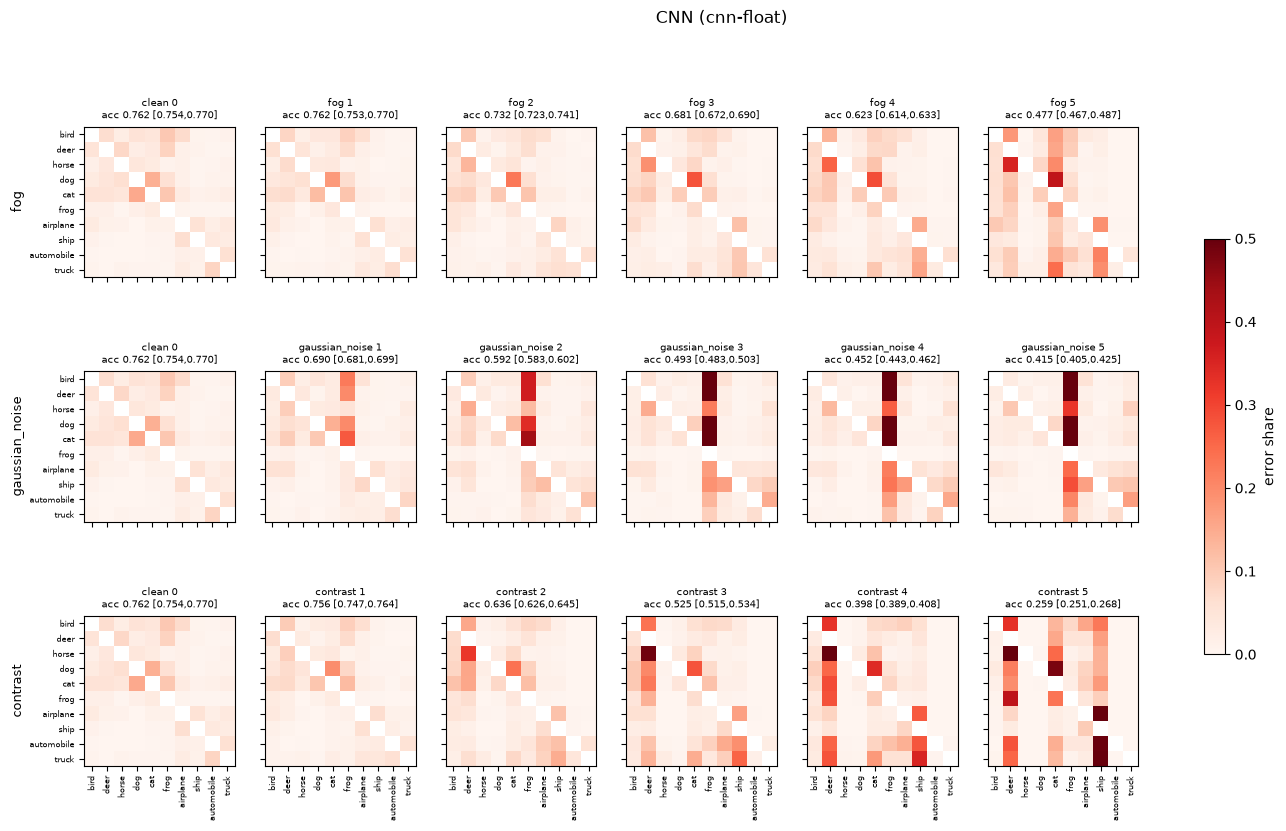

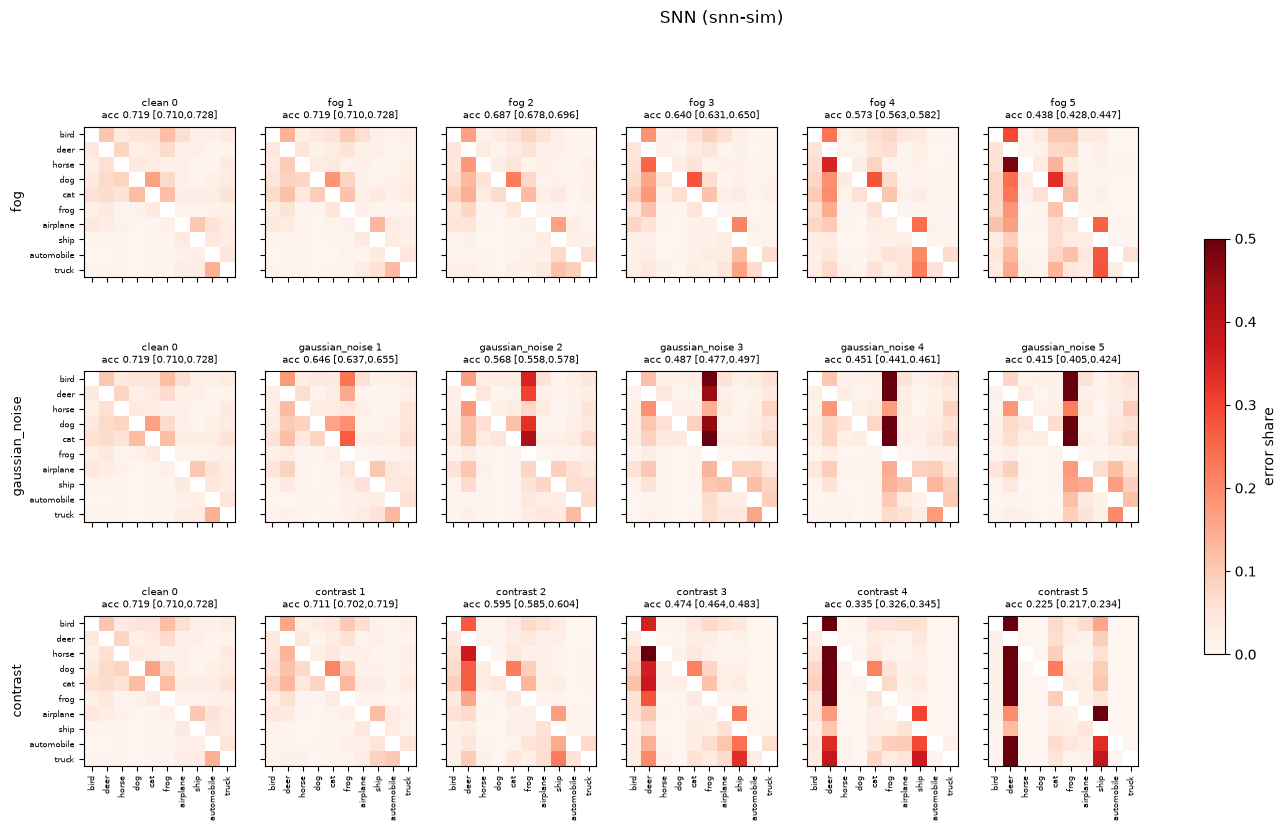

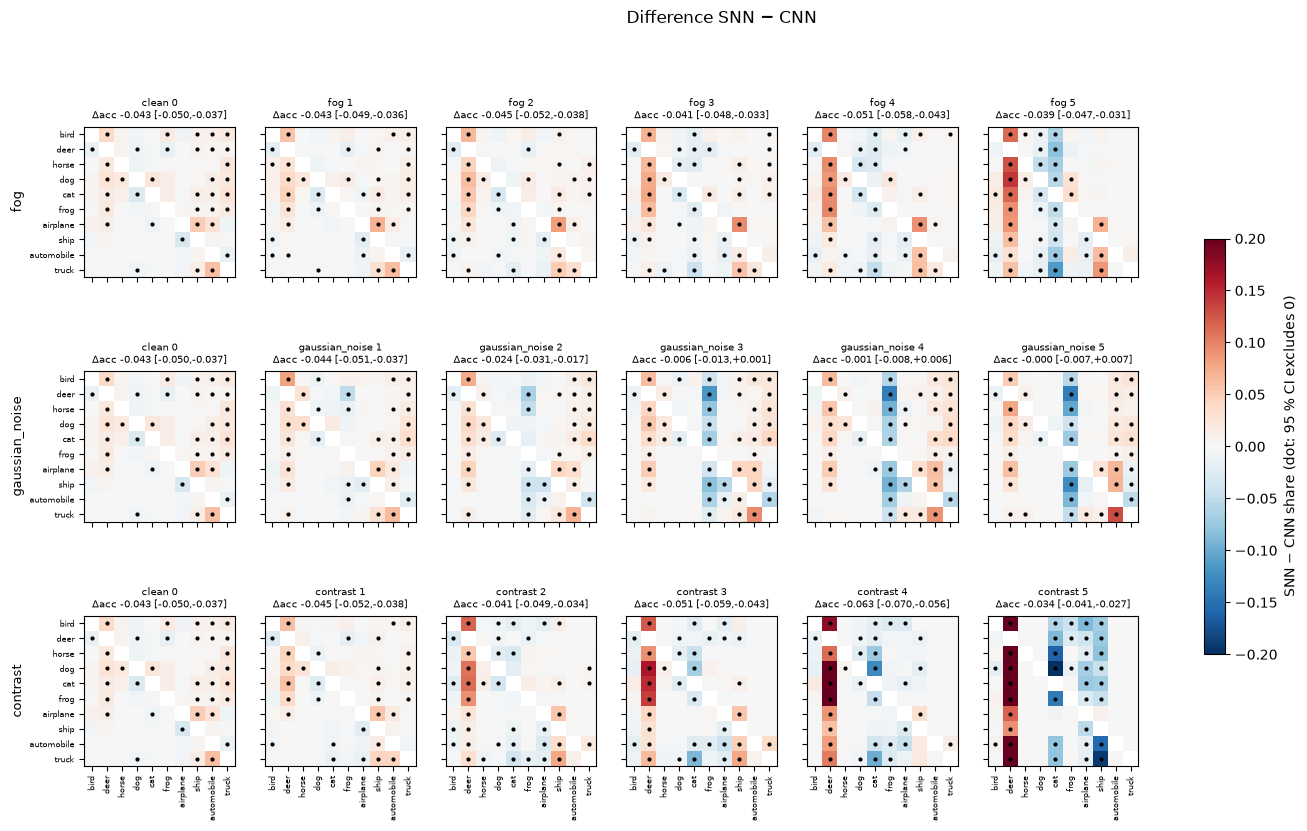

In [6]:
def err(m):
    m = m.copy()
    np.fill_diagonal(m, np.nan)
    return m[np.ix_(ORDER, ORDER)]

for kind in ["cnn", "snn", "diff"]:
    fig, axs = plt.subplots(len(CORRUPTIONS), 6, figsize=(17, 9), sharex=True, sharey=True)
    for i, corr in enumerate(CORRUPTIONS):
        for j, (c, s) in enumerate([("clean", 0)] + [(corr, s) for s in SEVERITIES]):
            d = W[(W.corruption == c) & (W.severity == s)]
            ax = axs[i, j]
            if kind == "diff":
                M = err(rate(d, "snn")) - err(rate(d, "cnn"))
                im = ax.imshow(M, cmap="RdBu_r", vmin=-.2, vmax=.2)
                sg = DIFF[(DIFF.corruption == c) & (DIFF.severity == s) & DIFF.sig & (DIFF.t != DIFF.p)]
                pos = {k: n for n, k in enumerate(ORDER)}
                ax.scatter([pos[p] for p in sg.p], [pos[t] for t in sg.t], s=4, c="k")
                dd, lo, hi, _ = paired_diff(d.cnn_ok, d.snn_ok)
                t = f"{c} {s}\nΔacc {dd:+.3f} [{lo:+.3f},{hi:+.3f}]"
            else:
                M = err(rate(d, kind))
                im = ax.imshow(M, cmap="Reds", vmin=0, vmax=.5)
                ok = d[f"{kind}_ok"]
                lo, hi = wilson(ok.sum(), len(ok))
                t = f"{c} {s}\nacc {ok.mean():.3f} [{lo:.3f},{hi:.3f}]"
            ax.set_title(t, fontsize=7)
            if j == 0:
                ax.set_ylabel(corr, fontsize=9)
    for ax in axs[-1]:
        ax.set_xticks(range(10))
        ax.set_xticklabels(NAMES, rotation=90, fontsize=6)
    for ax in axs[:, 0]:
        ax.set_yticks(range(10))
        ax.set_yticklabels(NAMES, fontsize=6)
    fig.colorbar(im, ax=axs, shrink=.6,
                 label="SNN − CNN share (dot: 95 % CI excludes 0)" if kind == "diff" else "error share")
    fig.suptitle({"cnn": f"CNN ({CNN})", "snn": f"SNN ({SNN})", "diff": "Difference SNN − CNN"}[kind])
    plt.show()

## Largest significant divergences
Top off-diagonal cells by |SNN − CNN|, only where the 95 % interval excludes 0, per corruption at severity 5.

In [7]:
top = off_sig[off_sig.severity == 5].assign(a=lambda x: x["diff"].abs())
top = top.sort_values("a", ascending=False).groupby("corruption").head(6)
top.assign(true=[CLASSES[t] for t in top.t], pred=[CLASSES[p] for p in top.p])[
    ["corruption", "true", "pred", "diff", "lo", "hi", "n"]].round(3)

,corruption,true,pred,diff,lo,hi,n
1554,contrast,dog,deer,0.415,0.383,0.447,1000
1534,contrast,cat,deer,0.380,0.348,0.412,1000
1564,contrast,frog,deer,0.344,0.311,0.377,1000
1594,contrast,truck,deer,0.292,0.263,0.321,1000
1524,contrast,bird,deer,0.289,0.259,0.319,1000
1574,contrast,horse,deer,0.265,0.236,0.294,1000
554,fog,dog,deer,0.141,0.117,0.165,1000
1046,gaussian_noise,deer,frog,-0.138,-0.162,-0.114,1000
1091,gaussian_noise,truck,automobile,0.131,0.110,0.152,1000
574,fog,horse,deer,0.127,0.100,0.154,1000


## H1/H2: named pairs across severity
Share of true-class images sent to the named class, with 95 % Wilson bands. Solid = CNN, dashed = SNN.

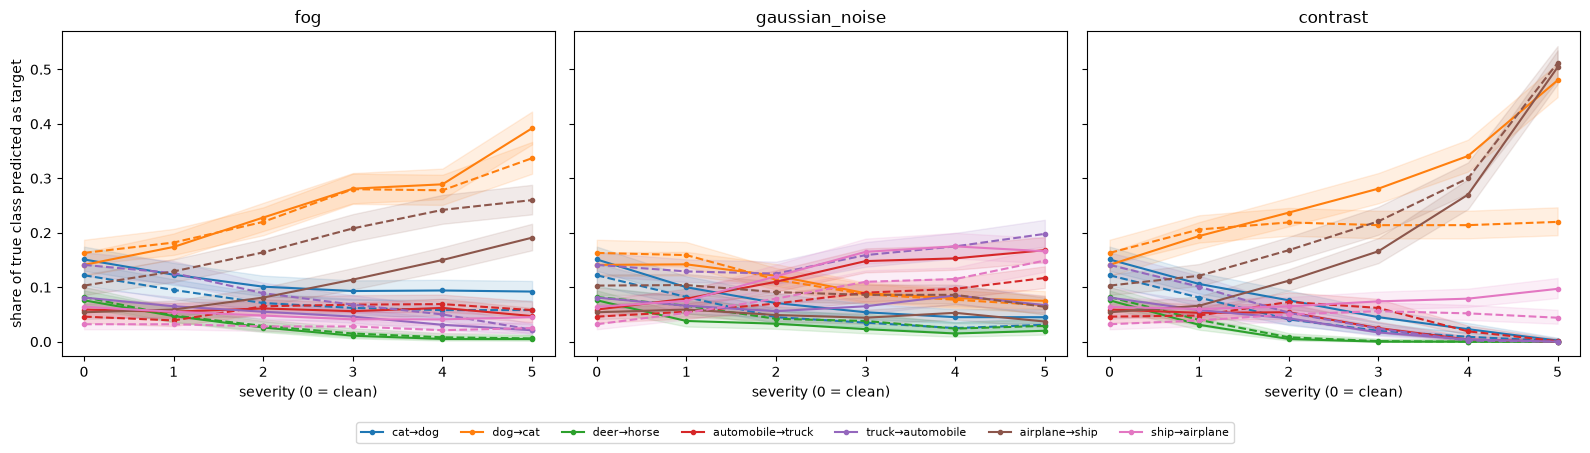

In [8]:
PAIRS = [("cat", "dog"), ("dog", "cat"), ("deer", "horse"),
         ("automobile", "truck"), ("truck", "automobile"), ("airplane", "ship"), ("ship", "airplane")]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
colors = plt.cm.tab10(np.arange(len(PAIRS)))
for ax, corr in zip(axs, CORRUPTIONS):
    for (t, p), col in zip(PAIRS, colors):
        for m, ls in (("cnn", "-"), ("snn", "--")):
            ys, los, his = [], [], []
            for s in [0] + SEVERITIES:
                d = W[(W.corruption == (corr if s else "clean")) & (W.severity == s)
                      & (W.label == CLASSES.index(t))]
                k = (d[f"pred_{m}"] == CLASSES.index(p)).sum()
                lo, hi = wilson(k, len(d))
                ys.append(k / len(d))
                los.append(lo)
                his.append(hi)
            ax.plot([0] + SEVERITIES, ys, ls, color=col, marker="o", ms=3,
                    label=f"{t}→{p}" if (m == "cnn" and corr == CORRUPTIONS[0]) else None)
            ax.fill_between([0] + SEVERITIES, los, his, color=col, alpha=.12)
    ax.set_title(corr)
    ax.set_xlabel("severity (0 = clean)")
axs[0].set_ylabel("share of true class predicted as target")
fig.legend(fontsize=8, ncol=7, loc="lower center", bbox_to_anchor=(.5, -.08))
plt.tight_layout()
plt.show()

## Where do the errors go? Sink classes
Share of *all wrong* predictions that land in each class. A class that absorbs errors as severity grows is a 'sink'.

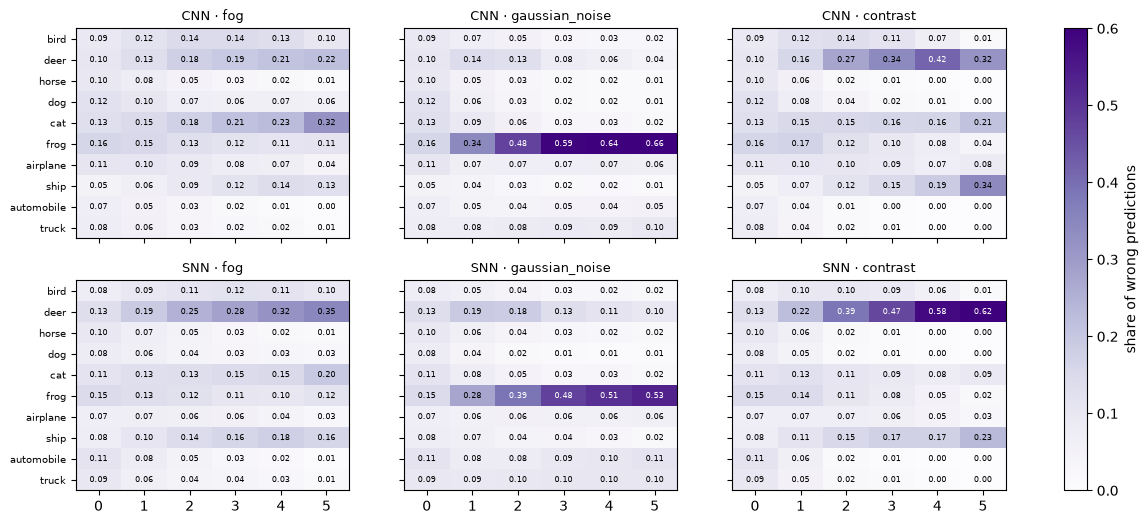

In [9]:
rows = []
for (c, s), d in W.groupby(["corruption", "severity"], sort=False):
    for m in ("cnn", "snn"):
        wrong = d[~d[f"{m}_ok"]]
        share = np.bincount(wrong[f"pred_{m}"].astype(int), minlength=10) / max(len(wrong), 1)
        rows += [(c, s, m, CLASSES[k], share[k], len(wrong)) for k in range(10)]
SINK = pd.DataFrame(rows, columns=["corruption", "severity", "model", "pred", "share", "n_wrong"])
fig, axs = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey=True)
for i, m in enumerate(("cnn", "snn")):
    for j, corr in enumerate(CORRUPTIONS):
        d = SINK[(SINK.model == m) & SINK.corruption.isin(["clean", corr])]
        H = d.pivot_table(index="pred", columns="severity", values="share").reindex(NAMES)
        im = axs[i, j].imshow(H.values, cmap="Purples", vmin=0, vmax=.6, aspect="auto")
        for (r, cc), v in np.ndenumerate(H.values):
            axs[i, j].text(cc, r, f"{v:.2f}", ha="center", va="center", fontsize=6,
                           color="w" if v > .35 else "k")
        axs[i, j].set_title(f"{m.upper()} · {corr}", fontsize=9)
        axs[i, j].set_xticks(range(6))
        axs[i, j].set_yticks(range(10))
        axs[i, j].set_yticklabels(NAMES, fontsize=7)
fig.colorbar(im, ax=axs, label="share of wrong predictions")
plt.show()

## Drill-down: images behind a cell

In [10]:
from lab.data import load_clean, load_corrupted

_X = {}
def images(c, s):
    if (c, s) not in _X:
        _X[(c, s)] = load_clean()[0] if c == "clean" else load_corrupted(c, s)[0]
    return _X[(c, s)]

def thumbs(df, n=24, cols=8, title=""):
    """The actual (corrupted) images behind a selection of rows of W."""
    df = df.head(n)
    if df.empty:
        print("nothing selected")
        return
    rows = int(np.ceil(len(df) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(cols * 1.35, rows * 1.75), squeeze=False)
    for ax in axs.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axs.flat, df.iterrows()):
        ax.imshow(images(r.corruption, int(r.severity))[int(r.image_id)])
        ax.set_title(f"#{int(r.image_id)} {CLASSES[r.label][:5]}\n"
                     f"C:{CLASSES[int(r.pred_cnn)][:5]} S:{CLASSES[int(r.pred_snn)][:5]}", fontsize=6.5)
    fig.suptitle(title, fontsize=9)
    plt.tight_layout()
    plt.show()

427 images: SNN says deer, CNN does not


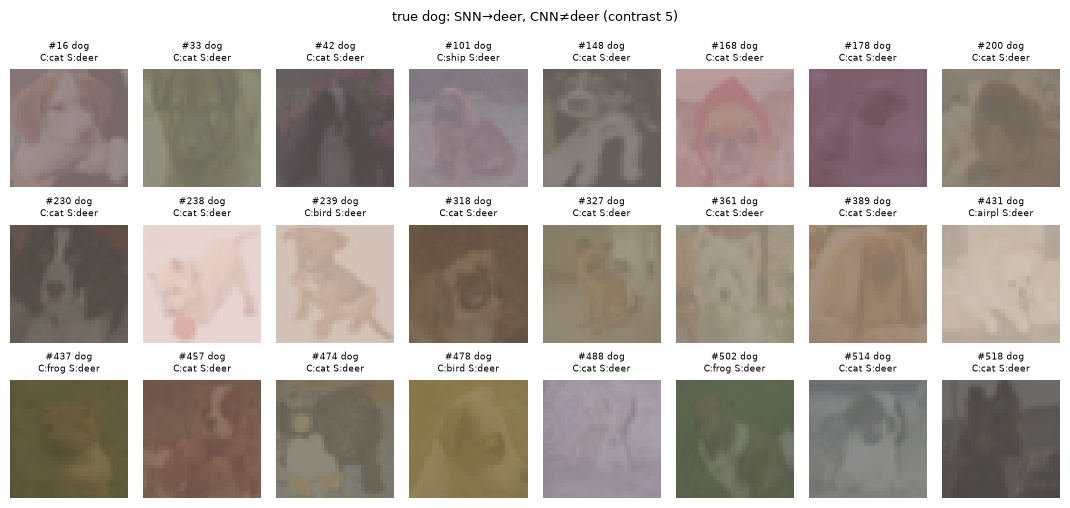

In [11]:
T, P, CORR, SEV = "dog", "deer", "contrast", 5     # largest divergence; change to inspect any cell
sel = W[(W.label == CLASSES.index(T)) & (W.corruption == CORR) & (W.severity == SEV)
        & (W.pred_snn == CLASSES.index(P)) & (W.pred_cnn != CLASSES.index(P))]
print(len(sel), f"images: SNN says {P}, CNN does not")
thumbs(sel, title=f"true {T}: SNN→{P}, CNN≠{P} ({CORR} {SEV})")

## Findings (01 confusion views)

Run: `cnn-float` vs `snn-sim`, 10 000 test images per condition, **regenerated** CIFAR-10-C.
All intervals are 95 %. Re-check on the official data and the final models.

1. **The SNN has a constant clean gap, and fog keeps it constant.** Clean: SNN − CNN accuracy
   −4.3 pp [−5.0, −3.7]. Under fog the gap stays between −3.9 and −5.0 pp at every severity.
   Both models lose the same amount (fog 5: CNN −28.5 pp, SNN −28.1 pp from clean).
2. **Errors collapse into a few "sink" classes as severity grows.** On clean images the errors
   are spread out (the largest target takes 13–16 % of wrong predictions). At severity 5 one or
   two classes absorb most errors:
   - noise → frog (CNN 66 %, SNN 53 % of wrong predictions)
   - contrast → ship 34 % and deer 32 % (CNN), deer 62 % (SNN)
   - fog → cat 32 % (CNN), deer 35 % (SNN)
3. **The main CNN/SNN divergence is *which* sink, not random noise.** The SNN pulls errors into
   **deer**. At contrast 5 it predicts deer for 55.7 % of *all* images, against 29.0 % for the
   CNN. The largest significant cells are all in the deer column: dog→deer +41.5 pp
   [38.3, 44.7], cat→deer +38.0, frog→deer +34.4, truck→deer +29.2 (contrast 5), and
   dog→deer +14.1 (fog 5). Under noise the direction flips for frog: the SNN sends fewer images
   to frog than the CNN (deer→frog −13.8 pp, ship→frog −12.4) and more trucks to automobile
   (+13.1).
4. **H1 is refuted.** Confusion within similar animal pairs does *not* grow: cat→dog *falls*
   with severity for both models under all three corruptions, and deer→horse drops to about 0.
   dog→cat grows under fog/contrast only because cat is a CNN sink. Under contrast the SNN's
   dog→cat flattens at about 0.22 while the CNN's reaches 0.48, because the SNN's dogs go to
   deer instead.
5. **H2 is partly supported.** airplane→ship grows strongly under fog and contrast (about 0.5
   for both models at contrast 5; fog 5: SNN 0.26 vs CNN 0.19). automobile↔truck grows only
   under noise (to about 0.15–0.20). ship→airplane does not grow.
6. **Drill-down (dog→deer, contrast 5, 427 images):** washed-out, low-saturation dogs on flat
   backgrounds. The CNN mostly calls them *cat*, the SNN calls them *deer*. Both are wrong; the
   models disagree about which sink.
7. 41.7 % of off-diagonal cells differ significantly. Most of these are small (a few pp) and
   already present on clean images. The large effects are column-shaped (sinks), not scattered.

**Guess, untested (Phase II):** heavily corrupted inputs are flat and low in texture, so few
units stay active, and the SNN's 4-bit output for "little activity" lands on deer. Phase II's
layer activity per corruption can test this directly.
